First five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Dataset shape:
(20640, 10)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
me

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


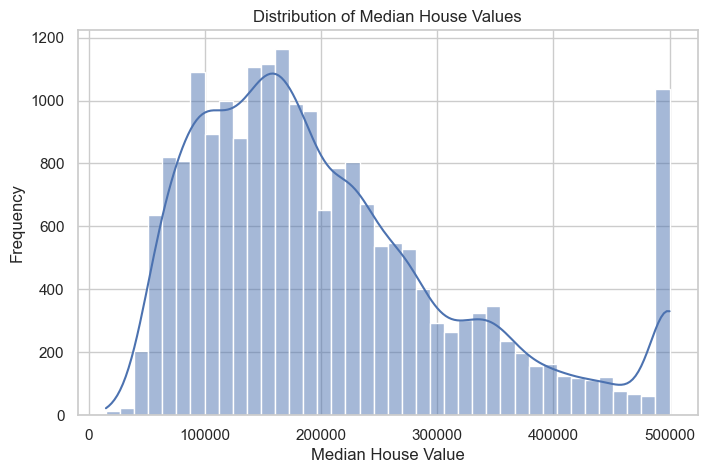

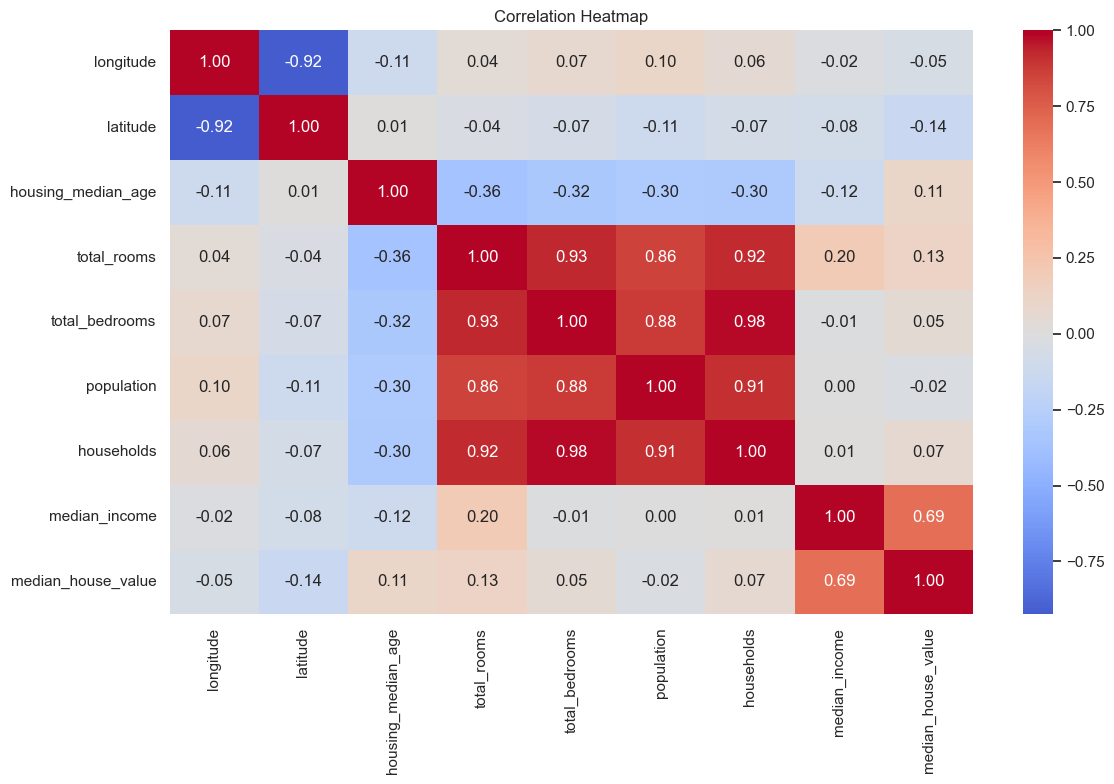

Features:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY



Target values:


0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64


Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Training samples: 16512
Testing samples: 4128
Preprocessing pipeline created successfully.
OLS Regression training completed.
Best Ridge alpha: 0.01
Ridge Regression training completed.
Best Lasso alpha: 0.01
Lasso Regression training completed.
Model Performance Comparison:


,RMSE,MAE,R2 Score
OLS,66788.296,47282.111,0.660
Ridge,66842.355,47318.801,0.659
Lasso,67355.521,47834.658,0.654


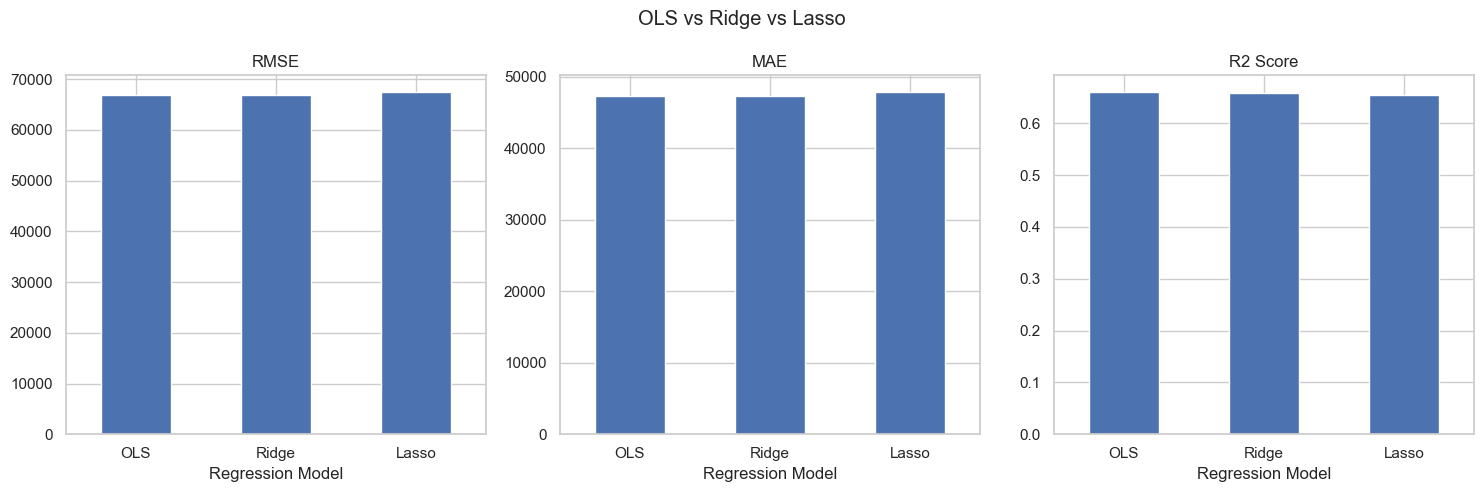

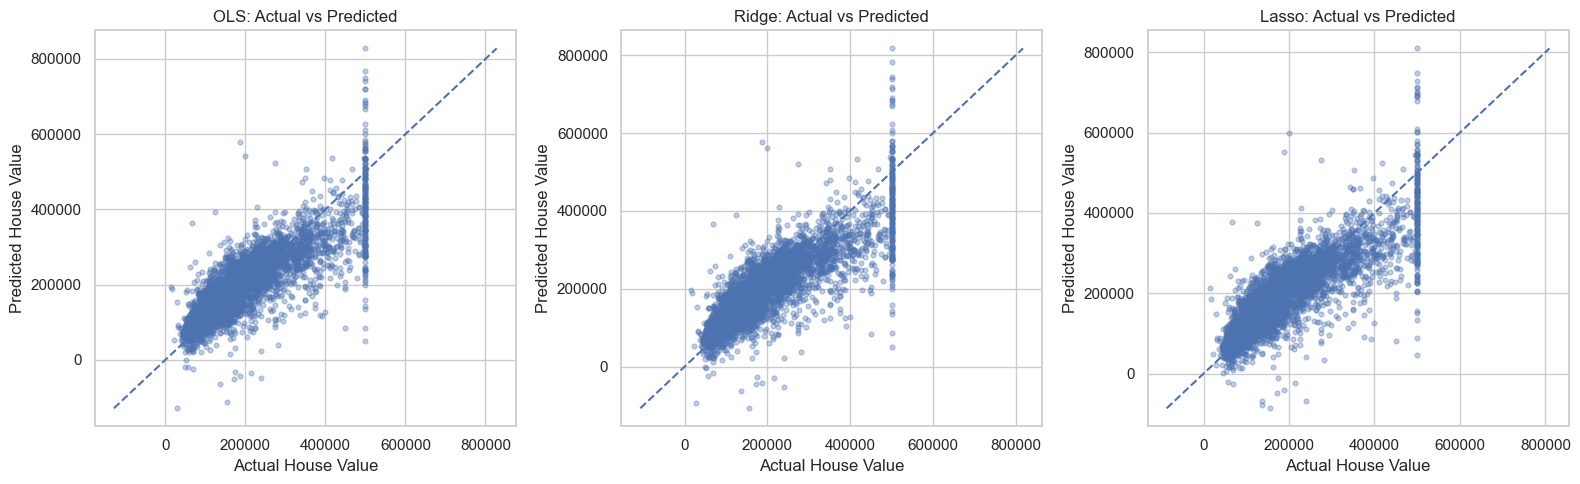

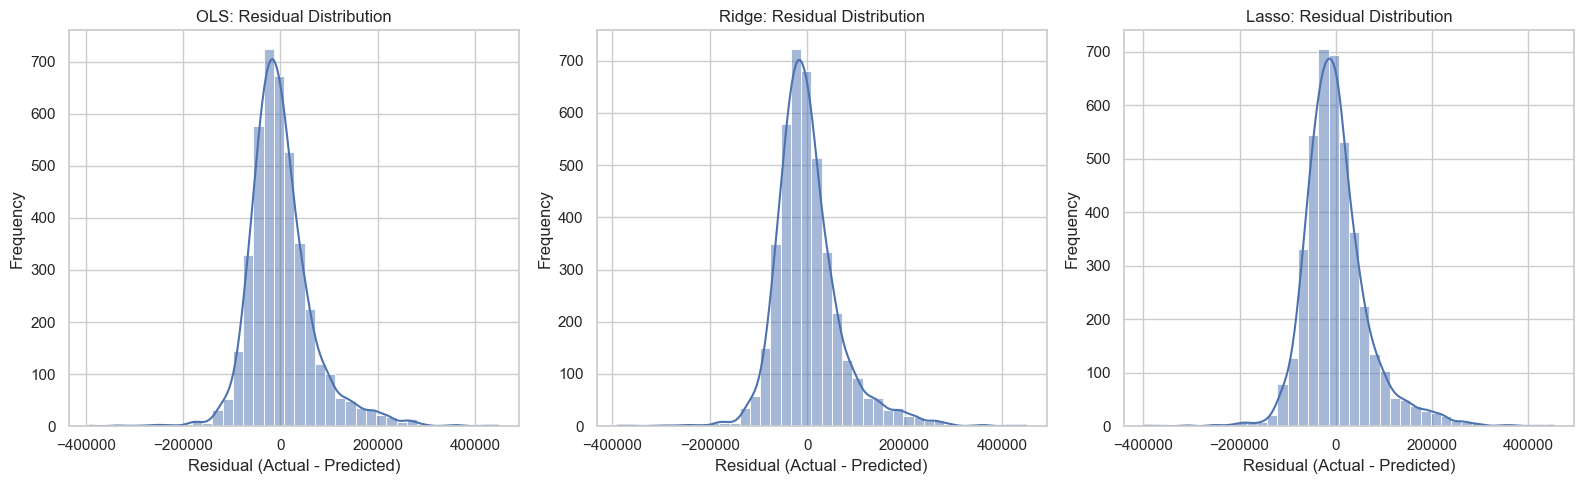

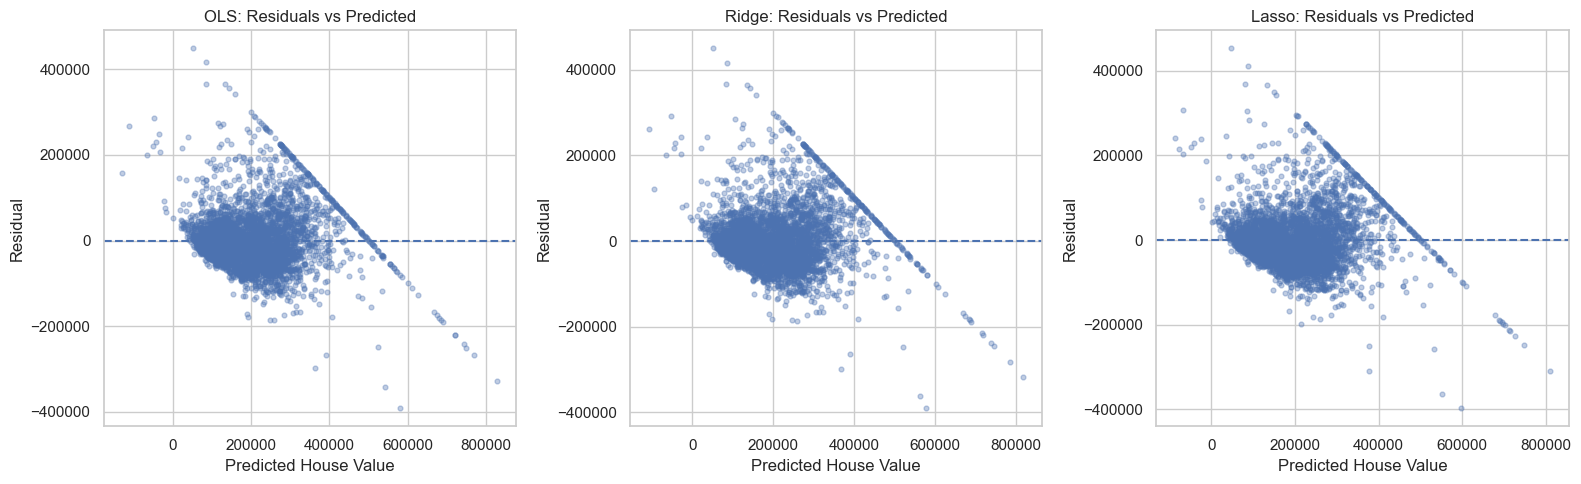

FINAL MODEL COMPARISON


,RMSE,MAE,R2 Score
OLS,66788.296,47282.111,0.660
Ridge,66842.355,47318.801,0.659
Lasso,67355.521,47834.658,0.654



Best model by RMSE: OLS
Best model by MAE: OLS
Best model by R²: OLS

Best Ridge alpha: 0.01
Best Lasso alpha: 0.01


In [4]:
### Cell 1: Import Libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")


### Cell 2: Load the California Housing Dataset


url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("First five rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())


### Cell 3: Exploratory Data Analysis

# Distribution of house prices

plt.figure(figsize=(8, 5))

sns.histplot(
    df["median_house_value"],
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()


### Cell 4: Correlation Heatmap


numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### Cell 5: Separate Features and Target


target = "median_house_value"

# Remove rows only if the target is missing
df = df.dropna(subset=[target]).copy()

X = df.drop(columns=[target])
y = df[target]

print("Features:")
display(X.head())

print("\nTarget values:")
display(y.head())

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)


### Cell 6: Split the Dataset


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


### Cell 7: Handle Missing Values, Encode Categories, and Scale Features




# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),

    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),

    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


### Cell 8: Train OLS Regression



ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
ols_model.fit(X_train, y_train)

# Make predictions
ols_pred = ols_model.predict(X_test)

print("OLS Regression training completed.")


### Cell 9: Train Ridge Regression Using GridSearchCV




alpha_values = [0.01, 0.1, 1, 10, 100]

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={
        "regressor__alpha": alpha_values
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_

ridge_pred = ridge_model.predict(X_test)

print("Best Ridge alpha:", ridge_search.best_params_["regressor__alpha"])
print("Ridge Regression training completed.")


### Cell 10: Train Lasso Regression Using GridSearchCV




lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={
        "regressor__alpha": alpha_values
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

lasso_model = lasso_search.best_estimator_

lasso_pred = lasso_model.predict(X_test)

print("Best Lasso alpha:", lasso_search.best_params_["regressor__alpha"])
print("Lasso Regression training completed.")


### Cell 11: Evaluate Models Using RMSE, MAE, and R²


def evaluate_model(y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mae = mean_absolute_error(y_true, y_pred)

    r2 = r2_score(y_true, y_pred)

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }


# Evaluate each model
results = {
    "OLS": evaluate_model(y_test, ols_pred),
    "Ridge": evaluate_model(y_test, ridge_pred),
    "Lasso": evaluate_model(y_test, lasso_pred)
}

results_df = pd.DataFrame(results).T

print("Model Performance Comparison:")

display(results_df.round(3))




### Cell 12: Plot Model Performance


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["RMSE", "MAE", "R2 Score"]

for ax, metric in zip(axes, metrics):

    results_df[metric].plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel("Regression Model")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("OLS vs Ridge vs Lasso")
plt.tight_layout()
plt.show()


### Cell 13: Plot Actual vs Predicted Values


predictions = {
    "OLS": ols_pred,
    "Ridge": ridge_pred,
    "Lasso": lasso_pred
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    ax.scatter(
        y_test,
        pred,
        alpha=0.35,
        s=12
    )

    lower = min(y_test.min(), pred.min())
    upper = max(y_test.max(), pred.max())

    # Perfect prediction reference line
    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    ax.set_title(name + ": Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.tight_layout()
plt.show()


### Cell 14: Plot Residual Distributions


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test.to_numpy() - pred

    sns.histplot(
        residuals,
        kde=True,
        bins=40,
        ax=ax
    )

    ax.set_title(name + ": Residual Distribution")
    ax.set_xlabel("Residual (Actual - Predicted)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


### Cell 15: Plot Residuals vs Predicted Values


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test.to_numpy() - pred

    ax.scatter(
        pred,
        residuals,
        alpha=0.35,
        s=12
    )

    ax.axhline(
        y=0,
        linestyle="--"
    )

    ax.set_title(name + ": Residuals vs Predicted")
    ax.set_xlabel("Predicted House Value")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()


### Cell 16: Final Comparison and Conclusion


print("FINAL MODEL COMPARISON")
print("=" * 50)

display(results_df.round(3))

best_rmse = results_df["RMSE"].idxmin()
best_mae = results_df["MAE"].idxmin()
best_r2 = results_df["R2 Score"].idxmax()

print("\nBest model by RMSE:", best_rmse)
print("Best model by MAE:", best_mae)
print("Best model by R²:", best_r2)

print("\nBest Ridge alpha:",
      ridge_search.best_params_["regressor__alpha"])

print("Best Lasso alpha:",
      lasso_search.best_params_["regressor__alpha"])

# Optional: save metrics to CSV
# results_df.to_csv("housing_model_comparison.csv")

